<a href="https://colab.research.google.com/github/kyeshineh/Dioxin-Food-Contamination/blob/main/EDA%2C%20Figures%20and%20Multiple%20Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:

import pandas as pd

# Step 1: Load the original dataset
df = pd.read_csv("dioxin_data.csv", low_memory=False)

print("Original dataset:", df.shape)

# Step 2: Rename columns to make them easier to use
df = df.rename(columns={
    "Sample No. - No. d'echantillon": "Sample_ID",
    "Date Sampled - Date d'echantillonage": "Date_Sampled",
    "Percent Fat - Pourcentage de graisse": "Fat_Percent",
    "Result - Resultat": "Result"
})

# Step 3: Remove extra spaces from text columns
for col in ["Sample_ID", "Component", "Origin", "Product"]:
    df[col] = df[col].astype("string").str.strip()

# Standardize unknown origins
df["Origin"] = df["Origin"].replace({
    "Unknown": "UNKNOWN",
    "": "UNKNOWN"
}).fillna("UNKNOWN")

# Step 4: Convert measurements to numeric values
df["Result"] = pd.to_numeric(
    df["Result"], errors="coerce"
)

df["Fat_Percent"] = pd.to_numeric(
    df["Fat_Percent"], errors="coerce"
)

# Step 5: Convert sampling dates to date format
df["Date_Sampled"] = pd.to_datetime(
    df["Date_Sampled"],
    format="%d-%b-%Y",
    errors="coerce"
)

# Step 6: Check for duplicate chemical measurements
duplicates = df.duplicated(
    subset=["Sample_ID", "Component"]
)

print("Duplicate sample-component records:",
      duplicates.sum())

if duplicates.any():
    raise ValueError(
        "Duplicate measurements found. Inspect before continuing."
    )

# Step 7: Check that sample information is consistent
metadata_cols = [
    "Date_Sampled",
    "Origin",
    "Product",
    "Fat_Percent"
]

conflicts = df.groupby("Sample_ID")[metadata_cols].nunique(
    dropna=False
)

if (conflicts > 1).any().any():
    raise ValueError(
        "Conflicting sample information found."
    )

# Step 8: Keep one row of information per sample
sample_info = df[
    ["Sample_ID", "Date_Sampled",
     "Origin", "Product", "Fat_Percent"]
].drop_duplicates(subset="Sample_ID").copy()

# Extract the sampling year
sample_info["Year"] = sample_info["Date_Sampled"].dt.year

# Step 9: Convert chemical measurements from rows to columns
chemical_data = df.pivot(
    index="Sample_ID",
    columns="Component",
    values="Result"
)

# Remove the column index label
chemical_data.columns.name = None

# Make Sample_ID a regular column again
chemical_data = chemical_data.reset_index()

# Step 10: Combine sample information and chemicals
data_cleaned = sample_info.merge(
    chemical_data,
    on="Sample_ID",
    how="left",
    validate="one_to_one"
)

# Step 11: Organize the columns
first_columns = [
    "Sample_ID",
    "Date_Sampled",
    "Year",
    "Origin",
    "Product",
    "Fat_Percent"
]

chemical_columns = [
    col for col in data_cleaned.columns
    if col not in first_columns
]

data_cleaned = data_cleaned[
    first_columns + chemical_columns
]

# Step 12: Check missing values
print("\nMissing values:")
print(data_cleaned.isna().sum())

# Check unknown origins
print("\nUnknown origins:")
print(
    data_cleaned["Origin"].eq("UNKNOWN").sum()
)

# Check unusual fat percentages
invalid_fat = (
    data_cleaned["Fat_Percent"].notna() &
    ~data_cleaned["Fat_Percent"].between(0, 100)
)

print("\nFat percentages outside 0-100%:")
print(invalid_fat.sum())

# Step 13: Save the cleaned dataset
data_cleaned.to_csv(
    "data_cleaned.csv",
    index=False
)

# Step 14: Display results
print("\nCleaning completed successfully!")

print("Original dataset:", df.shape)
print("Cleaned dataset:", data_cleaned.shape)

print("Unique samples:",
      data_cleaned["Sample_ID"].nunique())

print("Chemical measurements:",
      len(chemical_columns))

print("\nFirst five rows:")
print(data_cleaned.head())

print("\nSaved as: data_cleaned.csv")


Original dataset: (96565, 17)
Duplicate sample-component records: 0

Missing values:
Sample_ID                                         0
Date_Sampled                                      0
Year                                              0
Origin                                            0
Product                                           0
Fat_Percent                                      11
1234678-HpCDD                                     0
1234678-HpCDF                                     0
12346789-OCDD                                     0
12346789-OCDF                                     0
123478-HxCDD                                      0
123478-HxCDF                                      0
1234789-HpCDF                                     0
123678-HxCDD                                      0
123678-HxCDF                                      0
12378-PeCDD                                       0
12378-PeCDF                                       0
123789-HxCDD                   

In [8]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the cleaned dataset
df = pd.read_csv("data_cleaned.csv")

# Select the predictors and target variable
features = ["Product", "Origin", "Fat_Percent", "Year"]
target = "Total UB TEQ"

X = df[features]
y = df[target]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Identify categorical and numerical variables
categorical = ["Product", "Origin"]
numerical = ["Fat_Percent", "Year"]

# Prepare categorical variables
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Prepare numerical variables
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical),
    ("numerical", numerical_pipeline, numerical)
])

# Build the baseline Linear Regression model
baseline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

# Train the model
baseline.fit(X_train, y_train)

# Predict Total UB TEQ for test samples
y_pred = baseline.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION BASELINE")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("MAE:", round(mae, 5))
print("RMSE:", round(rmse, 5))
print("R²:", round(r2, 5))

# Display actual versus predicted concentrations
results = pd.DataFrame({
    "Actual_UB_TEQ": y_test.values,
    "Predicted_UB_TEQ": y_pred
})

print("\nFirst 10 predictions:")
print(results.head(10))


LINEAR REGRESSION BASELINE
Training samples: 2492
Testing samples: 623
MAE: 0.0651
RMSE: 0.11567
R²: -0.56191

First 10 predictions:
   Actual_UB_TEQ  Predicted_UB_TEQ
0       0.019137          0.070551
1       0.190478          0.093036
2       0.008517          0.086785
3       0.036250          0.085699
4       0.067469          0.123370
5       0.146164          0.130997
6       0.072126          0.085544
7       0.073838          0.080337
8       0.136055          0.160360
9       0.135307          0.100741


Total samples: 3115
Training samples: 2492
Testing samples: 623

Multiple Linear Regression model trained!

RESEARCH QUESTION 1 RESULTS
-----------------------------
MAE: 0.06527
RMSE: 0.11572
R²: -0.56323

First 10 predictions:
   Actual_UB_TEQ  Predicted_UB_TEQ
0       0.019137          0.073955
1       0.190478          0.092260
2       0.008517          0.088518
3       0.036250          0.084111
4       0.067469          0.123515
5       0.146164          0.133249
6       0.072126          0.084771
7       0.073838          0.083624
8       0.136055          0.159478
9       0.135307          0.098946


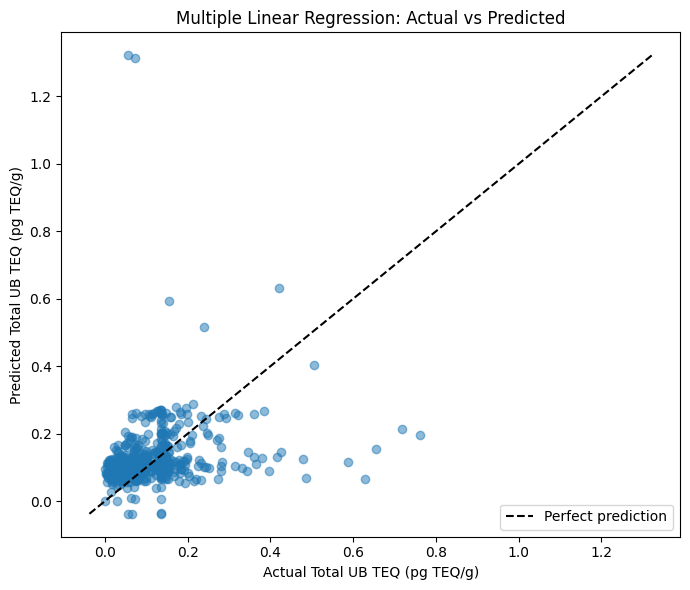


Research Question 1 analysis completed!


In [9]:

# =====================================================
# RESEARCH QUESTION 1
# Multiple Linear Regression Baseline Model
# CFIA Dioxin Dataset
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# -----------------------------------------------------
# STEP 1: Load cleaned dataset
# -----------------------------------------------------

df = pd.read_csv("data_cleaned.csv")

print("Total samples:", len(df))

# -----------------------------------------------------
# STEP 2: Select independent and dependent variables
# -----------------------------------------------------

# Independent variables (food characteristics)
X = df[["Product", "Fat_Percent", "Origin"]]

# Dependent variable (dioxin concentration)
y = df["Total UB TEQ"]

# -----------------------------------------------------
# STEP 3: Split into training and testing datasets
# -----------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# -----------------------------------------------------
# STEP 4: Prepare categorical and numerical variables
# -----------------------------------------------------

# Categorical variables
categorical_features = ["Product", "Origin"]

# Numerical variable
numerical_features = ["Fat_Percent"]

# Convert categorical variables into numerical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Handle missing fat percentage values
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("categorical", categorical_transformer, categorical_features),
    ("numerical", numerical_transformer, numerical_features)
])

# -----------------------------------------------------
# STEP 5: Build Multiple Linear Regression model
# -----------------------------------------------------

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

# -----------------------------------------------------
# STEP 6: Train the baseline model
# -----------------------------------------------------

model.fit(X_train, y_train)

print("\nMultiple Linear Regression model trained!")

# -----------------------------------------------------
# STEP 7: Predict dioxin concentrations
# -----------------------------------------------------

y_pred = model.predict(X_test)

# -----------------------------------------------------
# STEP 8: Evaluate model performance
# -----------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nRESEARCH QUESTION 1 RESULTS")
print("-----------------------------")
print("MAE:", round(mae, 5))
print("RMSE:", round(rmse, 5))
print("R²:", round(r2, 5))

# -----------------------------------------------------
# STEP 9: Display actual and predicted values
# -----------------------------------------------------

results = pd.DataFrame({
    "Actual_UB_TEQ": y_test.values,
    "Predicted_UB_TEQ": y_pred
})

print("\nFirst 10 predictions:")
print(results.head(10))

# Save results
results.to_csv("RQ1_linear_predictions.csv", index=False)

# -----------------------------------------------------
# STEP 10: Visualize actual vs predicted concentrations
# -----------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual Total UB TEQ (pg TEQ/g)")
plt.ylabel("Predicted Total UB TEQ (pg TEQ/g)")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()

plt.savefig("RQ1_linear_regression.png", dpi=300)
plt.show()

print("\nResearch Question 1 analysis completed!")



Analyzing: Fat Percentage
MAE: 0.06261
RMSE: 0.08974
R²: 0.05989

Analyzing: Country of Origin
MAE: 0.06976
RMSE: 0.12882
R²: -0.9373

Analyzing: Product Category
MAE: 0.06101
RMSE: 0.0898
R²: 0.05856

Analyzing: All Three Characteristics
MAE: 0.06529
RMSE: 0.11572
R²: -0.56339

RESEARCH QUESTION 1: MODEL RESULTS
               Predictors     MAE    RMSE       R2
           Fat Percentage 0.06261 0.08974  0.05989
        Country of Origin 0.06976 0.12882 -0.93730
         Product Category 0.06101 0.08980  0.05856
All Three Characteristics 0.06529 0.11572 -0.56339


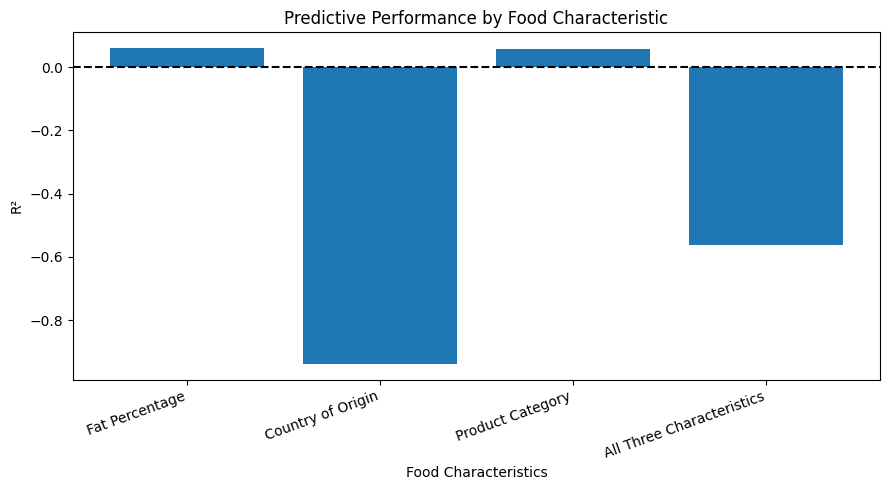

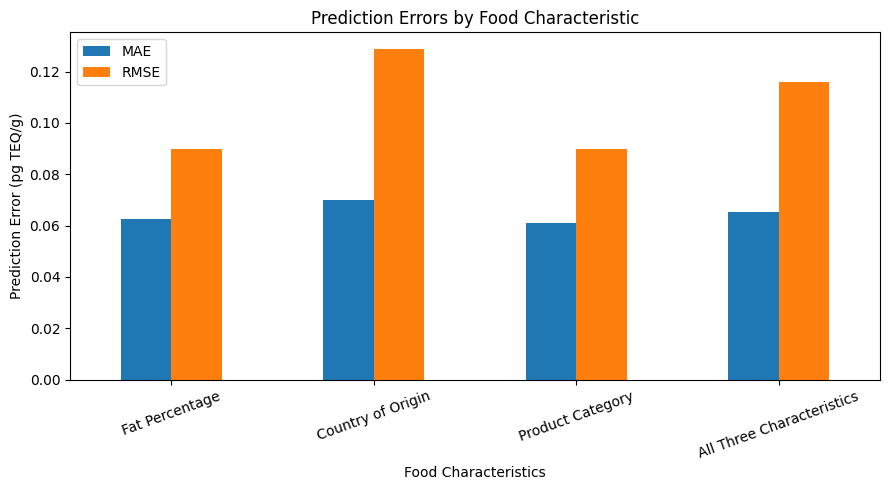

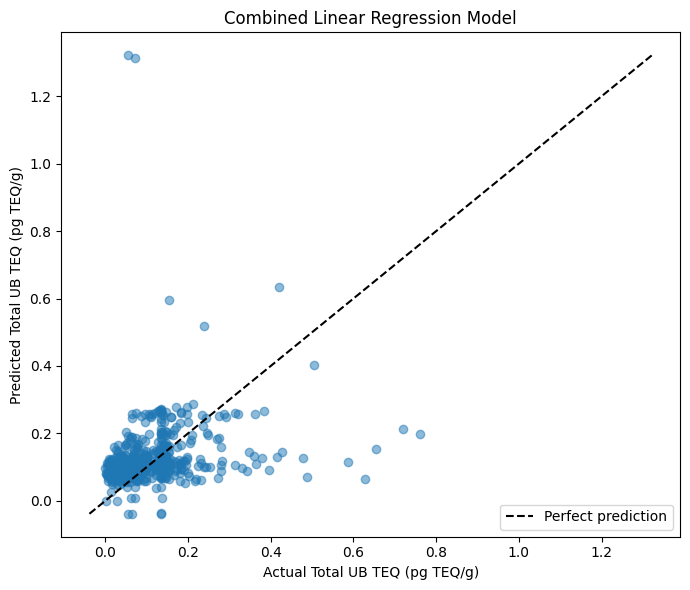


Research Question 1 analysis completed!


In [10]:

# =====================================================
# RESEARCH QUESTION 1
# Multiple Linear Regression
# Individual and combined food characteristics
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# STEP 1: Load the cleaned dataset
df = pd.read_csv("data_cleaned.csv")

# STEP 2: Define the target variable
y = df["Total UB TEQ"]

# Define the four predictor combinations
feature_groups = {
    "Fat Percentage": ["Fat_Percent"],
    "Country of Origin": ["Origin"],
    "Product Category": ["Product"],
    "All Three Characteristics": [
        "Fat_Percent", "Origin", "Product"
    ]
}

# STEP 3: Create one consistent train/test split
# The same samples will be used for all four models
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42
)

results = []
predictions = {}

# STEP 4: Train and evaluate each model
for name, features in feature_groups.items():

    print("\nAnalyzing:", name)

    X = df[features]

    X_train = X.loc[train_idx]
    X_test = X.loc[test_idx]

    y_train = y.loc[train_idx]
    y_test = y.loc[test_idx]

    # Identify categorical and numerical predictors
    categorical = [
        col for col in features
        if col in ["Origin", "Product"]
    ]

    numerical = [
        col for col in features
        if col == "Fat_Percent"
    ]

    # Prepare the transformations
    transformers = []

    if categorical:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(
                strategy="most_frequent"
            )),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ])

        transformers.append((
            "categorical",
            categorical_pipeline,
            categorical
        ))

    if numerical:
        numerical_pipeline = Pipeline([
            ("imputer", SimpleImputer(
                strategy="median"
            ))
        ])

        transformers.append((
            "numerical",
            numerical_pipeline,
            numerical
        ))

    preprocessor = ColumnTransformer(transformers)

    # Build the Linear Regression model
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("regression", LinearRegression())
    ])

    # Train the model
    model.fit(X_train, y_train)

    # Predict Total UB TEQ
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Predictors": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    predictions[name] = y_pred

    print("MAE:", round(mae, 5))
    print("RMSE:", round(rmse, 5))
    print("R²:", round(r2, 5))

# STEP 5: Create the comparison table
comparison = pd.DataFrame(results)

print("\nRESEARCH QUESTION 1: MODEL RESULTS")
print(comparison.round(5).to_string(index=False))

comparison.to_csv("RQ1_characteristic_comparison.csv", index=False)

# STEP 6: Graph the individual R² values
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Predictors"],
    comparison["R2"]
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Predictive Performance by Food Characteristic")
plt.xlabel("Food Characteristics")
plt.ylabel("R²")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig("RQ1_characteristic_R2.png", dpi=300)
plt.show()

# STEP 7: Graph the prediction errors
comparison.plot(
    x="Predictors",
    y=["MAE", "RMSE"],
    kind="bar",
    figsize=(9, 5),
    rot=20
)

plt.title("Prediction Errors by Food Characteristic")
plt.xlabel("Food Characteristics")
plt.ylabel("Prediction Error (pg TEQ/g)")
plt.tight_layout()

plt.savefig("RQ1_characteristic_errors.png", dpi=300)
plt.show()

# STEP 8: Plot actual vs predicted for combined model
plt.figure(figsize=(7, 6))

combined_pred = predictions["All Three Characteristics"]
actual = y.loc[test_idx]

plt.scatter(actual, combined_pred, alpha=0.5)

minimum = min(actual.min(), combined_pred.min())
maximum = max(actual.max(), combined_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual Total UB TEQ (pg TEQ/g)")
plt.ylabel("Predicted Total UB TEQ (pg TEQ/g)")
plt.title("Combined Linear Regression Model")
plt.legend()
plt.tight_layout()

plt.savefig("RQ1_combined_predictions.png", dpi=300)
plt.show()

print("\nResearch Question 1 analysis completed!")


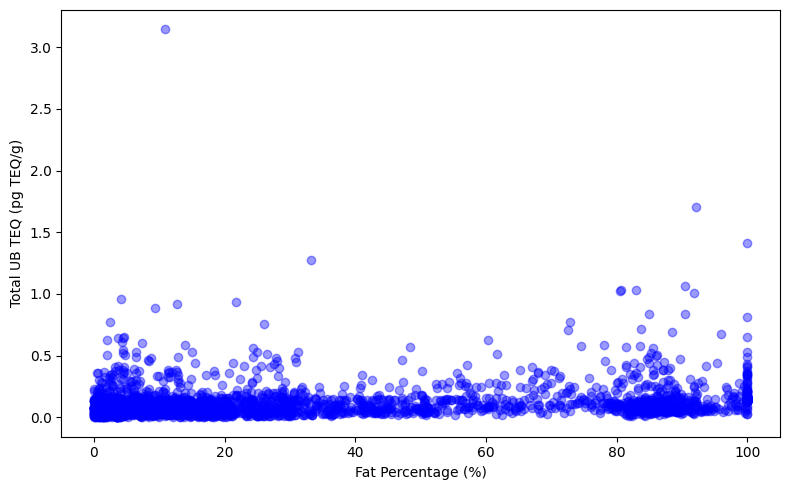

In [18]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
df = pd.read_csv("data_cleaned.csv")

# Keep valid fat percentages
fat_data = df[df["Fat_Percent"].between(0, 100)]

# Create Figure 2
plt.figure(figsize=(8, 5))

plt.scatter(
    fat_data["Fat_Percent"],
    fat_data["Total UB TEQ"],
    color="blue",
    alpha=0.4
)

plt.title("")
plt.xlabel("Fat Percentage (%)")
plt.ylabel("Total UB TEQ (pg TEQ/g)")

plt.tight_layout()
plt.savefig("EDA_2_fat_vs_TEQ.png", dpi=300)
plt.show()


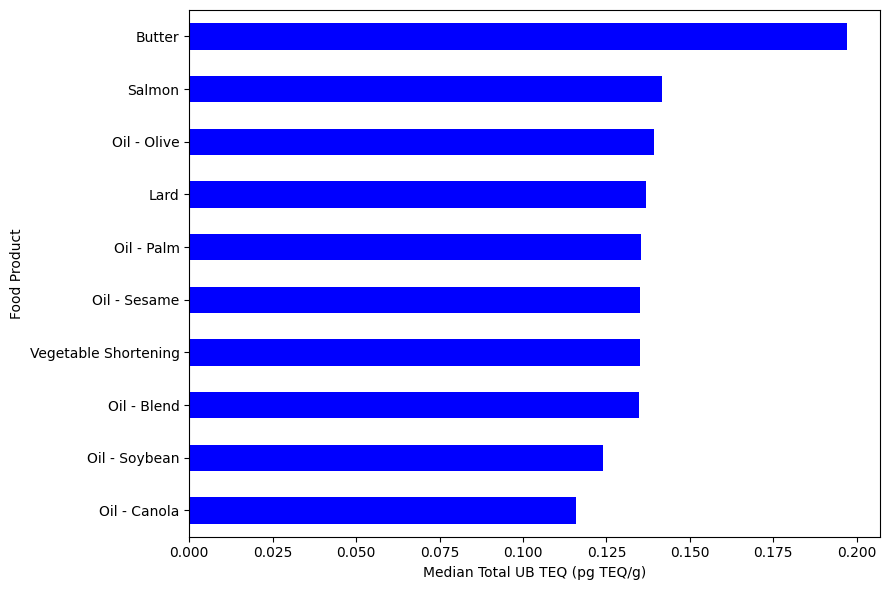

In [19]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
df = pd.read_csv("data_cleaned.csv")

# Calculate the median Total UB TEQ for each food product
product_summary = df.groupby("Product")["Total UB TEQ"].agg(
    ["count", "median"]
)

# Only include products with at least 30 samples
product_summary = product_summary[
    product_summary["count"] >= 30
]

# Select the 10 products with the highest median
top_products = product_summary.sort_values(
    "median", ascending=False
).head(10)

# Create Figure 3
plt.figure(figsize=(9, 6))

top_products["median"].sort_values().plot(
    kind="barh",
    color="blue"
)

plt.title("")
plt.xlabel("Median Total UB TEQ (pg TEQ/g)")
plt.ylabel("Food Product")

plt.tight_layout()
plt.savefig("EDA_3_product_TEQ.png", dpi=300)
plt.show()


Total UB TEQ by Country of Origin
               count   median     mean
Origin                                
CANADA           671  0.09234  0.11543
CHINA             53  0.12856  0.16592
FRANCE            91  0.06597  0.09289
INDIA             39  0.11342  0.15539
ITALY             47  0.13489  0.19158
THAILAND          84  0.08119  0.10486
UNITED STATES    791  0.07243  0.10792
UNKNOWN          970  0.08342  0.11273


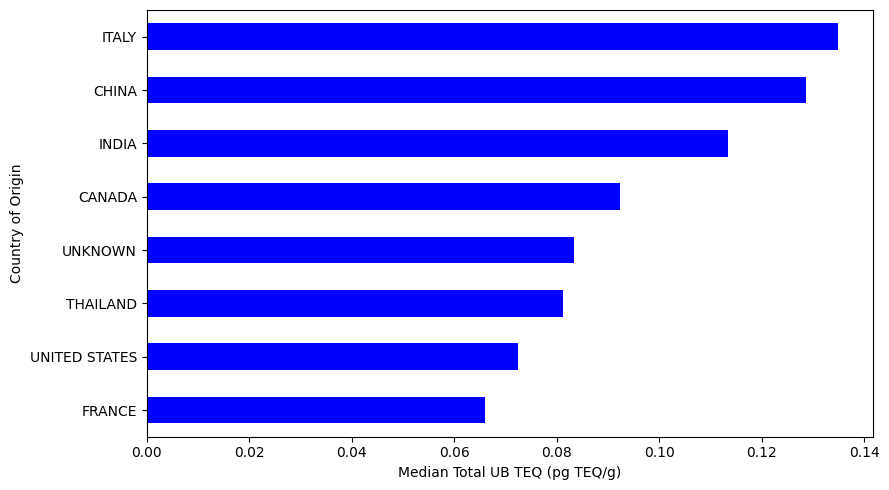

In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
df = pd.read_csv("data_cleaned.csv")

# Select the 8 most frequently reported origins
top_origins = df["Origin"].value_counts().head(8).index

# Keep samples from these origins
origin_data = df[df["Origin"].isin(top_origins)]

# Calculate median Total UB TEQ for each origin
origin_summary = origin_data.groupby("Origin")["Total UB TEQ"].agg(
    ["count", "median", "mean"]
)

# Print the summary
print("Total UB TEQ by Country of Origin")
print(origin_summary.round(5))

# Create Figure 4
plt.figure(figsize=(9, 5))

origin_summary["median"].sort_values().plot(
    kind="barh",
    color="blue"
)

plt.title("")
plt.xlabel("Median Total UB TEQ (pg TEQ/g)")
plt.ylabel("Country of Origin")

plt.tight_layout()
plt.savefig("EDA_4_origin_TEQ.png", dpi=300)
plt.show()


Number of Food Samples by Year
Year
2014    587
2015    837
2016    701
2017    536
2018    408
2019     46
Name: count, dtype: int64


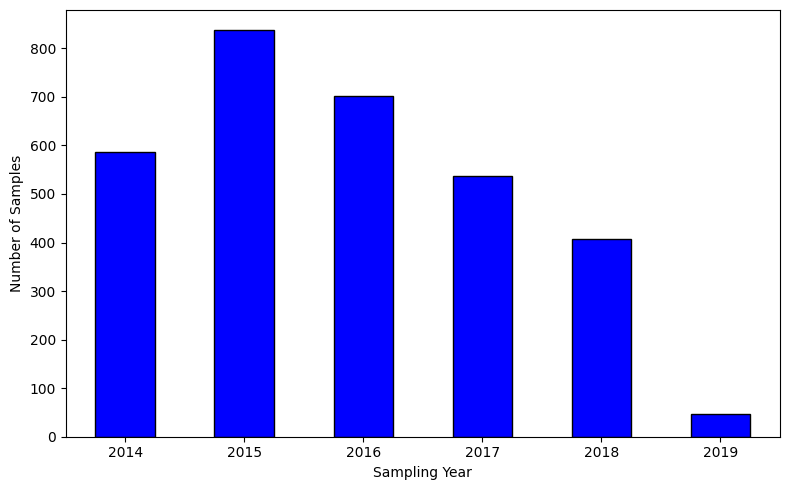

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
df = pd.read_csv("data_cleaned.csv")

# Count the number of samples collected each year
year_counts = df["Year"].value_counts().sort_index()

# Print the number of samples per year
print("Number of Food Samples by Year")
print(year_counts)

# Create Figure 5
plt.figure(figsize=(8, 5))

year_counts.plot(
    kind="bar",
    color="blue",
    edgecolor="black"
)

plt.title("")
plt.xlabel("Sampling Year")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("EDA_5_samples_by_year.png", dpi=300)
plt.show()


In [11]:

# =====================================================
# RESEARCH QUESTION 1
# Train/Test Validation and Data Leakage Checks
# =====================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# STEP 1: Load cleaned data
df = pd.read_csv("data_cleaned.csv")

# Check that each sample appears only once
assert df["Sample_ID"].notna().all(), "Missing sample IDs"
assert df["Sample_ID"].is_unique, "Duplicate sample IDs found"

print("Unique sample ID check: PASSED")

# STEP 2: Select predictors and target
features = ["Product", "Fat_Percent", "Origin"]
target = "Total UB TEQ"

X = df[features].copy()
y = df[target].copy()
sample_ids = df["Sample_ID"].copy()

# Ensure the target is complete
assert y.notna().all(), "Missing target values found"

# Ensure target-related chemical data are excluded
assert target not in X.columns
assert "Total LB TEQ" not in X.columns
assert "Sample_ID" not in X.columns

print("Target leakage feature check: PASSED")

# STEP 3: Split all data together
X_train, X_test, y_train, y_test, id_train, id_test = (
    train_test_split(
        X,
        y,
        sample_ids,
        test_size=0.20,
        random_state=42
    )
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# STEP 4: Check for sample overlap
overlap = set(id_train).intersection(set(id_test))

print("\nShared sample IDs:", len(overlap))

assert len(overlap) == 0, "Data leakage: overlapping samples!"

print("Sample overlap check: PASSED")

# STEP 5: Define preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline,
     ["Product", "Origin"]),
    ("numerical", numerical_pipeline,
     ["Fat_Percent"])
])

# STEP 6: Build Linear Regression pipeline
model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

# STEP 7: Fit ONLY on training data
model.fit(X_train, y_train)

print("Training-only preprocessing: PASSED")

# STEP 8: Evaluate ONLY on test data
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nBASELINE MODEL RESULTS")
print("MAE:", round(mae, 5))
print("RMSE:", round(rmse, 5))
print("R²:", round(r2, 5))

print("\nValidation checks completed successfully!")


Unique sample ID check: PASSED
Target leakage feature check: PASSED

Training samples: 2492
Testing samples: 623

Shared sample IDs: 0
Sample overlap check: PASSED
Training-only preprocessing: PASSED

BASELINE MODEL RESULTS
MAE: 0.06527
RMSE: 0.11572
R²: -0.56323

Validation checks completed successfully!


STEP 1: DATA LOADED
Dataset shape: (3115, 37)

STEP 2: FEATURES SELECTED
Predictors: ['Product', 'Fat_Percent', 'Origin']
Target: Total UB TEQ

STEP 3: DATA SPLIT
Training samples: 2492
Testing samples: 623
Overlapping sample IDs: 0

STEP 4: PREPROCESSING DEFINED
Categorical: One-hot encoding
Numerical: Median imputation
Scaling: Not applied

STEP 5: MODEL TRAINED
Algorithm: Multiple Linear Regression

STEP 6: PREDICTIONS GENERATED

STEP 7: MODEL PERFORMANCE
MAE: 0.06527
RMSE: 0.11572
R²: -0.56323

STEP 8: FIRST 5 PREDICTIONS
     Sample_ID  Actual_UB_TEQ  Predicted_UB_TEQ
C2015DOXN00642       0.019137          0.073955
C2015DOXN00198       0.190478          0.092260
C2014DOXN00640       0.008517          0.088518
C2018DOXN00145       0.036250          0.084111
C2015DOXN00598       0.067469          0.123515


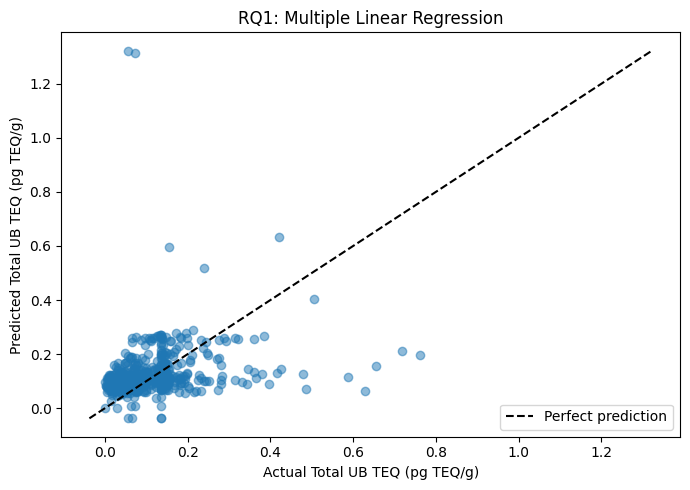


PIPELINE COMPLETED SUCCESSFULLY


In [12]:

# =====================================================
# CFIA DIOXIN PROJECT - RESEARCH QUESTION 1
# COMPLETE MULTIPLE LINEAR REGRESSION PIPELINE
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# STEP 1: LOAD DATA
df = pd.read_csv("data_cleaned.csv")

print("STEP 1: DATA LOADED")
print("Dataset shape:", df.shape)

# STEP 2: SELECT FEATURES AND TARGET
features = ["Product", "Fat_Percent", "Origin"]
target = "Total UB TEQ"

X = df[features]
y = df[target]
sample_ids = df["Sample_ID"]

print("\nSTEP 2: FEATURES SELECTED")
print("Predictors:", features)
print("Target:", target)

# STEP 3: TRAIN/TEST SPLIT
X_train, X_test, y_train, y_test, id_train, id_test = (
    train_test_split(
        X, y, sample_ids,
        test_size=0.20,
        random_state=42
    )
)

print("\nSTEP 3: DATA SPLIT")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Check for leakage between samples
overlap = set(id_train) & set(id_test)
assert len(overlap) == 0, "Sample overlap detected!"

print("Overlapping sample IDs:", len(overlap))

# STEP 4: PREPROCESSING
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline,
     ["Product", "Origin"]),
    ("numerical", numerical_pipeline,
     ["Fat_Percent"])
])

print("\nSTEP 4: PREPROCESSING DEFINED")
print("Categorical: One-hot encoding")
print("Numerical: Median imputation")
print("Scaling: Not applied")

# STEP 5: BUILD AND TRAIN MODEL
model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

print("\nSTEP 5: MODEL TRAINED")
print("Algorithm: Multiple Linear Regression")

# STEP 6: MAKE PREDICTIONS
y_pred = model.predict(X_test)

print("\nSTEP 6: PREDICTIONS GENERATED")

# STEP 7: EVALUATE MODEL
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nSTEP 7: MODEL PERFORMANCE")
print("MAE:", round(mae, 5))
print("RMSE:", round(rmse, 5))
print("R²:", round(r2, 5))

# STEP 8: SAVE MODEL OUTPUT
results = pd.DataFrame({
    "Sample_ID": id_test.values,
    "Actual_UB_TEQ": y_test.values,
    "Predicted_UB_TEQ": y_pred
})

print("\nSTEP 8: FIRST 5 PREDICTIONS")
print(results.head().to_string(index=False))

results.to_csv("RQ1_pipeline_predictions.csv", index=False)

# STEP 9: CREATE GRAPH
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual Total UB TEQ (pg TEQ/g)")
plt.ylabel("Predicted Total UB TEQ (pg TEQ/g)")
plt.title("RQ1: Multiple Linear Regression")
plt.legend()
plt.tight_layout()

plt.savefig("RQ1_pipeline_output.png", dpi=300)
plt.show()

print("\nPIPELINE COMPLETED SUCCESSFULLY")


Missing values:
Sample_ID            0
Date_Sampled         0
Function             0
Origin               0
Product              0
Fat_Percent         11
UB_TEQ               0
TEQ_Unit             0
Year                 0
Fat_Out_Of_Range     0
Negative_TEQ         0
TEQ_IQR_Outlier      0
dtype: int64

Unknown origins:
970

Outlier threshold: 0.26786587725
Number of outliers: 213

Samples by year:
Year
2014    587
2015    837
2016    701
2017    536
2018    408
2019     46
Name: count, dtype: int64

Samples by product:
Product
Meal - Toddler/Baby    282
Cheese                 280
Meal - RTE             277
Beef                   134
Pork                   128
                      ... 
Cuttlefish               1
pork                     1
Bream                    1
Saury                    1
Anchovy                  1
Name: count, Length: 94, dtype: int64

Fat percentages above 100:
           Product  Fat_Percent
1804  Oil - Peanut        102.0


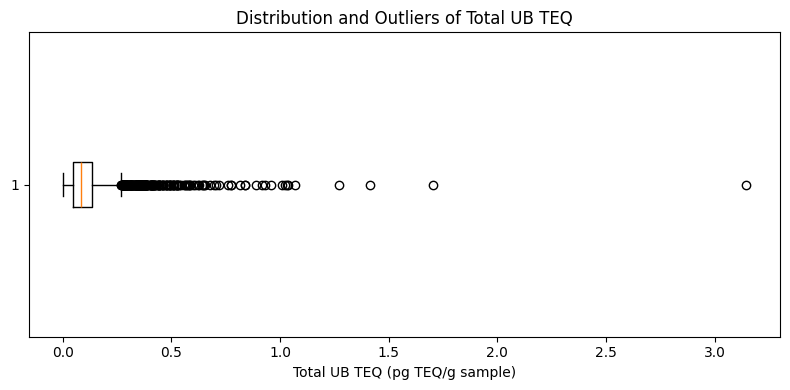

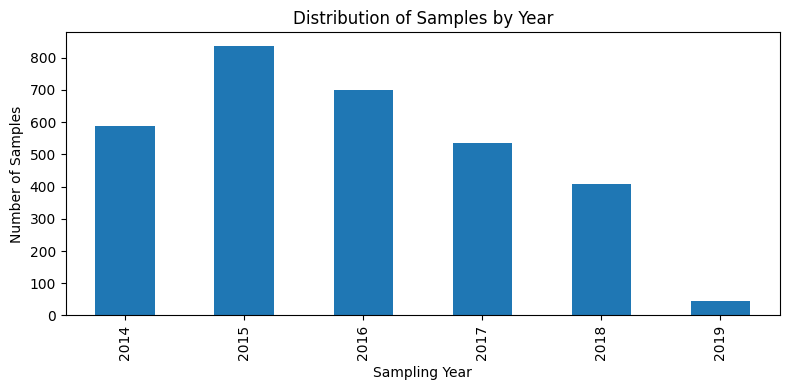

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned sample-level data
df = pd.read_csv("data_cleaned.csv")

# 1. Check missing values
print("Missing values:")
print(df.isna().sum())

# Check unknown origins separately
print("\nUnknown origins:")
print((df["Origin"].str.upper() == "UNKNOWN").sum())

# 2. Identify TEQ outliers using IQR
Q1 = df["UB_TEQ"].quantile(0.25)
Q3 = df["UB_TEQ"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["UB_TEQ"] < lower) |
    (df["UB_TEQ"] > upper)
]

print("\nOutlier threshold:", upper)
print("Number of outliers:", len(outliers))

# 3. Check imbalances
print("\nSamples by year:")
print(df["Year"].value_counts().sort_index())

print("\nSamples by product:")
print(df["Product"].value_counts())

# 4. Check unusual fat percentages
print("\nFat percentages above 100:")
print(df[df["Fat_Percent"] > 100][
    ["Product", "Fat_Percent"]
])

# 5. Create charts
plt.figure(figsize=(8, 4))
plt.boxplot(df["UB_TEQ"].dropna(), vert=False)
plt.xlabel("Total UB TEQ (pg TEQ/g sample)")
plt.title("Distribution and Outliers of Total UB TEQ")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
df["Year"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Sampling Year")
plt.ylabel("Number of Samples")
plt.title("Distribution of Samples by Year")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Load the original dataset
df = pd.read_csv("dioxin_data.csv")

# Check the first five rows
print(df.head())

# Check rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print(df.columns.tolist())

  Sample No. - No. d'echantillon Function Fonction   Origin  Origine Product  \
0                 C2014DOXN00001  Unknown  Inconnu  UNKNOWN  INCONNU    Lard   
1                 C2014DOXN00001  Unknown  Inconnu  UNKNOWN  INCONNU    Lard   
2                 C2014DOXN00001  Unknown  Inconnu  UNKNOWN  INCONNU    Lard   
3                 C2014DOXN00001  Unknown  Inconnu  UNKNOWN  INCONNU    Lard   
4                 C2014DOXN00001  Unknown  Inconnu  UNKNOWN  INCONNU    Lard   

    Produit Date Sampled - Date d'echantillonage  \
0  Saindoux                          03-Jun-2014   
1  Saindoux                          03-Jun-2014   
2  Saindoux                          03-Jun-2014   
3  Saindoux                          03-Jun-2014   
4  Saindoux                          03-Jun-2014   

                        Type of Test                           Type d'analyse  \
0  Dioxins and Dioxin-like Compounds  Les dioxines et les composés semblables   
1  Dioxins and Dioxin-like Compounds  Les di

/tmp/ipykernel_1732/3111166837.py:5: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("dioxin_data.csv")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!pip install word2number
import pandas as pd
from word2number import w2n

def convert_to_number(value):

    # Keep missing values as missing
    if pd.isna(value):
        return float("nan")

    # First, try converting regular numeric values
    try:
        return float(value)
    except (ValueError, TypeError):
        pass

    # Next, try converting numbers written as words
    try:
        return float(w2n.word_to_num(str(value).strip().lower()))
    except (ValueError, TypeError):
        return float("nan")

In [ ]:
# Count missing values in each column
print(df.isnull().sum())

# Calculate percentage of missing values
missing_percent = df.isnull().mean() * 100

print(missing_percent.round(2))

Sample No. - No. d'echantillon              0
Function                                    0
Fonction                                    0
Origin                                      0
Origine                                     0
Product                                     0
Produit                                     0
Date Sampled - Date d'echantillonage        0
Type of Test                                0
Type d'analyse                              0
Component                                   0
Composant                                   0
Result - Resultat                           0
Result Unit - Unite de resultat             0
Limit of Detection / Limite de detection    0
Percent Fat - Pourcentage de graisse        0
Plan Code - Code du regime                  0
dtype: int64
Sample No. - No. d'echantillon              0.0
Function                                    0.0
Fonction                                    0.0
Origin                                      0.0
Origine      

In [ ]:
# Count completely identical rows
print("Duplicate rows:", df.duplicated().sum())

# Display duplicate rows
display(df[df.duplicated(keep=False)].head(10))
df_clean = df.drop_duplicates().copy()

print("Rows after removing exact duplicates:", len(df_clean))

Duplicate rows: 0


,Sample No. - No. d'echantillon,Function,Fonction,Origin,Origine,Product,Produit,Date Sampled - Date d'echantillonage,Type of Test,Type d'analyse,Component,Composant,Result - Resultat,Result Unit - Unite de resultat,Limit of Detection / Limite de detection,Percent Fat - Pourcentage de graisse,Plan Code - Code du regime


Rows after removing exact duplicates: 96565


In [ ]:
# Keep only the total upper-bound TEQ records
samples = df_clean[
    df_clean["Component"] == "Total UB TEQ"
].copy()

print("Rows after selecting Total UB TEQ:", len(samples))

display(samples.head())

Rows after selecting Total UB TEQ: 3115


,Sample No. - No. d'echantillon,Function,Fonction,Origin,Origine,Product,Produit,Date Sampled - Date d'echantillonage,Type of Test,Type d'analyse,Component,Composant,Result - Resultat,Result Unit - Unite de resultat,Limit of Detection / Limite de detection,Percent Fat - Pourcentage de graisse,Plan Code - Code du regime
30,C2014DOXN00001,Unknown,Inconnu,UNKNOWN,INCONNU,Lard,Saindoux,03-Jun-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.153360,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,100.0,2014_TS012
61,C2014DOXN00002,Unknown,Inconnu,UNKNOWN,INCONNU,Lard,Saindoux,03-Jun-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.152900,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,100.0,2014_TS012
92,C2014DOXN00003,Unknown,Inconnu,UNKNOWN,INCONNU,Mayonnaise,Mayonnaise,25-Nov-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.453620,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,78.2,2014_TS012
123,C2014DOXN00004,Import,Importé,UNKNOWN,INCONNU,Mayonnaise,Mayonnaise,25-Sep-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.093409,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,63.5,2014_TS012
154,C2014DOXN00005,Import,Importé,UNKNOWN,INCONNU,Mayonnaise,Mayonnaise,02-Jul-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.072057,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,70.0,2014_TS012


# New Section

In [ ]:
# Convert measured concentration to numeric
samples["UB_TEQ"] = pd.to_numeric(
    samples["Result - Resultat"],
    errors="coerce"
)

# Check conversion results
print("Missing UB TEQ values:", samples["UB_TEQ"].isna().sum())

print(samples["UB_TEQ"].describe())

Missing UB TEQ values: 0
count    3115.000000
mean        0.115934
std         0.129557
min         0.000029
25%         0.049240
50%         0.082332
75%         0.136690
max         3.143551
Name: UB_TEQ, dtype: float64


In [ ]:
fat_col = "Percent Fat - Pourcentage de graisse"

print(samples[fat_col].value_counts().head(15))
# Convert original values to strings
fat_values = samples[fat_col].astype(str).str.strip()

# Flag values such as <0.5
samples["fat_below_limit"] = fat_values.str.startswith("<")

# Convert exact numeric measurements
samples["fat_pct"] = pd.to_numeric(
    fat_values.where(~samples["fat_below_limit"]),
    errors="coerce"
)

print("Fat values below reporting limit:",
      samples["fat_below_limit"].sum())

print("Missing numerical fat values:",
      samples["fat_pct"].isna().sum())

Percent Fat - Pourcentage de graisse
100.0    243
0.5       33
0.5       23
0         22
1.3       14
1.8       13
0.6       13
1.9       12
3.5       12
0.6       12
2.5       11
1.5       10
0.8       10
1.1       10
<0.5      10
Name: count, dtype: int64
Fat values below reporting limit: 11
Missing numerical fat values: 11


Product
Meal - Toddler/Baby       282
Cheese                    280
Meal - RTE                277
Beef                      134
Pork                      128
Chicken                   101
Butter                     89
Infant Formula - Dairy     77
Mayonnaise                 76
Tuna                       74
Oil - Soybean              69
Salmon                     66
Pizza Products             64
Oil - Olive                62
Oil - Peanut               60
Name: count, dtype: Int64
Function
Import      1756
Unknown      688
Domestic     671
Name: count, dtype: Int64
Negative concentrations: 0
70524    3.143551
61968    1.704986
61441    1.415637
68540    1.272088
25016    1.067403
3006     1.035659
51862    1.031050
3223     1.023319
52730    1.007067
31960    0.958908
Name: UB_TEQ, dtype: float64


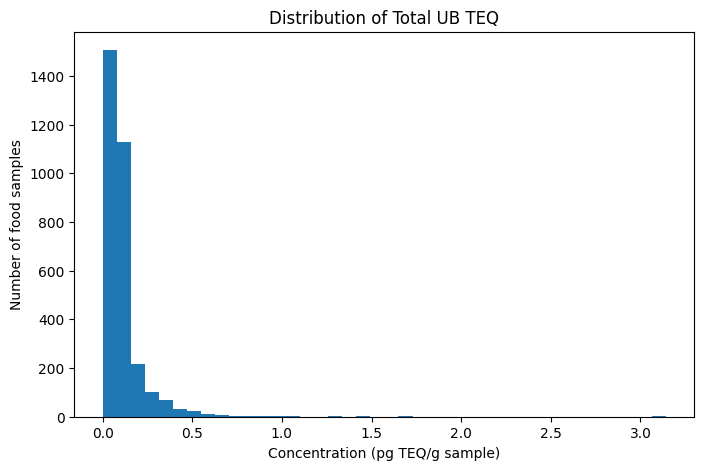

In [ ]:
# Remove accidental spaces
samples["Product"] = samples["Product"].astype("string").str.strip()
samples["Function"] = samples["Function"].astype("string").str.strip()

# Check categories
print(samples["Product"].value_counts().head(15))

print(samples["Function"].value_counts(dropna=False))
# Check negative values
print("Negative concentrations:",
      (samples["UB_TEQ"] < 0).sum())

# Display highest measurements
print(samples["UB_TEQ"].nlargest(10))

# Examine the concentration distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(samples["UB_TEQ"].dropna(), bins=40)

plt.title("Distribution of Total UB TEQ")
plt.xlabel("Concentration (pg TEQ/g sample)")
plt.ylabel("Number of food samples")

plt.show()

In [ ]:
# Confirm the resulting dataset
print("Original rows:", len(df))
print("Cleaned sample-level rows:", len(samples))

print("\nMissing values in important columns:")
print(samples[["Product", "Function", "fat_pct", "UB_TEQ"]]
      .isna().sum())

print("\nSummary statistics:")
print(samples[["fat_pct", "UB_TEQ"]].describe())

display(samples.head())

Original rows: 96565
Cleaned sample-level rows: 3115

Missing values in important columns:
Product      0
Function     0
fat_pct     11
UB_TEQ       0
dtype: int64

Summary statistics:
           fat_pct       UB_TEQ
count  3104.000000  3115.000000
mean     33.034958     0.115934
std      35.352914     0.129557
min       0.000000     0.000029
25%       3.695000     0.049240
50%      16.000000     0.082332
75%      62.900000     0.136690
max     102.000000     3.143551


,Sample No. - No. d'echantillon,Function,Fonction,Origin,Origine,Product,Produit,Date Sampled - Date d'echantillonage,Type of Test,Type d'analyse,Component,Composant,Result - Resultat,Result Unit - Unite de resultat,Limit of Detection / Limite de detection,Percent Fat - Pourcentage de graisse,Plan Code - Code du regime,UB_TEQ,fat_below_limit,fat_pct
30,C2014DOXN00001,Unknown,Inconnu,UNKNOWN,INCONNU,Lard,Saindoux,03-Jun-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.153360,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,100.0,2014_TS012,0.153360,False,100.0
61,C2014DOXN00002,Unknown,Inconnu,UNKNOWN,INCONNU,Lard,Saindoux,03-Jun-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.152900,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,100.0,2014_TS012,0.152900,False,100.0
92,C2014DOXN00003,Unknown,Inconnu,UNKNOWN,INCONNU,Mayonnaise,Mayonnaise,25-Nov-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.453620,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,78.2,2014_TS012,0.453620,False,78.2
123,C2014DOXN00004,Import,Importé,UNKNOWN,INCONNU,Mayonnaise,Mayonnaise,25-Sep-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.093409,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,63.5,2014_TS012,0.093409,False,63.5
154,C2014DOXN00005,Import,Importé,UNKNOWN,INCONNU,Mayonnaise,Mayonnaise,02-Jul-2014,Dioxins and Dioxin-like Compounds,Les dioxines et les composés semblables,Total UB TEQ,LS TEQ totale,0.072057,pg TEQ/g sample / d’échantillon,Not applicable / Sans objet,70.0,2014_TS012,0.072057,False,70.0


In [ ]:
# Save the cleaned dataset
samples.to_csv("CFIA_cleaned_samples.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
